# EE-411 — Fundamentals of Inference and Learning

## Homework 2 — Unsupervised learning

### Part 1 — Classification with the K-means algorithm

The K-means algorithm is a fundamental tool in unsupervised learning. Consider a problem with a dataset $\mathcal{D} = \left\{x_i\right\}_{i=1}^n$ where $x_i \in \mathbb{R}^d$ with no labels. We aim to find hidden structure within the data, namely clusters in the dataset. Classifiers have been studied in the exercise sessions, mainly for supervised learning. Here, the data are not labeled.

The K-means algorithm tries to classify the dataset into $K$ clusters. Each cluster is represented by a centroid, meaning the average of the points within the cluster. We denote by $C_k$ the set of points of a cluster $k$ and $\mu_k$ its centroid. Then, the algorithm minimizes the intra-cluster variance, in other words, it tries to reduce the distance between the points of the cluster and the centroid.

More technically, the algorithm works iteratively in two main steps:

- Points are assigned to clusters based on their proximity to existing centroids.
- Centroids are updated by taking the average of the points assigned to each cluster.

The loss function of the problem can be written as:
$$J(\mu_1, ..., \mu_K) = \sum_{i=1}^{n} \, \lVert x_i - \mu(i)\rVert^2 \; ,$$
where $\mu(i)$ is the centroid of the cluster assigned to $x_i$.

Let us examine the choice of this loss function. Does it match the aforementioned rules? Then, can it help us understand whether the algorithm converges?

Additionally, until Question 8, we assume that the clusters $C_k$ are disjoint, especially at initialization.

#### Question 1

First, let us familiarize ourselves with the loss function:

- Prove the second equality:

   $$J(\mu_1, ..., \mu_K) = \sum_{i=1}^{n} \, \lVert x_i - \mu(i)\rVert^2 = \sum_{k=1}^{K} \sum_{x_i \in C_k} \, \lVert x_i - \mu_k \rVert^2$$

- What does the term $\sum_{x_i \in C_k} \, \lVert x_i - \mu_k \rVert^2$ represent?

- Explain why this form of the loss function is more convenient.

Proof: 
By assumption the clusters $C_k$ are disjoint. Since in the initial formula each $x_i$ has its own $\mu(i)$ each data point is assigned to a cluster. That means each data point belongs to exactly one cluster. 

Since the sum is finite, we can reorder the terms by grouping them in their clusters. And finally by definition we have $\mu(i)$ = $\mu_k$, k being the index of the cluster $x_i$ is in. 

This term represents the sum of squared deviation of each $x_i$ in a cluster to the centroid of this cluster. It is equal to the number of data points in the cluster times the empirical variance of the cluster, when $\mu_k$ is the mean of the cluster k.

This form is convenient since it lets us handle each cluster independently according to $\mu_k$ and a clusters inner data points. In the first formula $\mu(i)$ depends on the assignment for each term. Now we can solve K independent problems to minimize J.

#### Question 2

Let us focus on the first step of the algorithm. Consider a single point $x_i$ and introduce the time dependence. Also, we use a prime ($'$) to denote the variables after the new assignment of the data points.

The sequence of updates is: $(\cdot)^t \to (\cdot)^t\,{}' \to (\cdot)^{t+1} \to (\cdot)^{t+1}\,{}' \to (\cdot)^{t+2}$

Thus, at each time step $t$, the new assignments satisfy (no proof required):

$$ \mu^t(i)' = \operatorname*{arg\,min}_{\mu \in \left\{\mu^t_k\right\}_k} \lVert x_i - \mu \rVert^2$$

For instance, at time $t$ before new assignments, the vector $x_i$ belongs to a cluster $k$, while after the next assignment, it now belongs to the cluster $k'$ (it can be the same or different from the cluster $k$).

Thus, for the whole dataset, the algorithm updates the assignments as follows: $\left\{\mu^t(i) \right\} \to \left\{\mu^t(i)'\right\}$.

Compare $\lVert x_i - \mu^t(i) \rVert^2$ and $\lVert x_i - \mu^t(i)' \rVert^2$ for a given point.

Claim: $\lVert x_i - \mu^t(i) \rVert^2$ $\geq$ $\lVert x_i - \mu^t(i)' \rVert^2$

Proof by contradiction: 

Lets assume $\lVert x_i - \mu^t(i)' \rVert^2$ > $\lVert x_i - \mu^t(i) \rVert^2$. Since $\mu^t(i)$ is in $\left\{\mu^t_k\right\}_k$ and so one of the candidates, it would further minimze $\lVert x_i - \mu \rVert^2$. This shows a contradiction to the definition of $\mu^t(i)'$. So the first assumption was wrong and by that our claim proven.

#### Question 3

We recall that we use a prime ($'$) to denote the variables after the new assignment of the data points, so that: $\mu^t(i) \to \mu^t(i)'$ and $J_t \to J_t'$

Using the previous question, compare $J_t$ and ${J_t}'$.

Hint: Choose the appropriate expression from the two given for $J$.

The first expression is more appropriate, because during the assignment step only $\mu^t(i) \to \mu^t(i)'$ changes and the centroids are fixed. This lets us compare each term. 

$$J_t' = \sum_{i=1}^{n} \lVert x_i - \mu^t(i)' \rVert^2 \leq \sum_{i=1}^{n} \lVert x_i - \mu^t(i) \rVert^2 = J_t .$$

Since every term in the sum is less or equal to before by Q2. The sum gets less or equal to the sum before. that means : 
$J_t$ $\geq$ $J_t'$. 
Equality holds only iff no $\mu_t(i)$ gets an strictly closer update to $x_i$. For example $\mu_t(i)$ doesn't change or it changes between two equally distant centroids from $x_i$.

#### Question 4

Next, consider the second step of the algorithm, which minimizes the intra-cluster variance:

$$ \left\{\mu^{t+1}_k\right\}_k = \operatorname*{arg\,min}_{\left\{\mu_k\right\}_k \in \mathbb{R}^d} J'_t\left( \left\{\mu_k\right\}_k \right) = \operatorname*{arg\,min}_{\left\{\mu_k\right\}_k \in \mathbb{R}^d} \sum_{k=1}^{K} \sum_{x_i \in C^t_k{}'} \, \lVert x_i - \mu_k \rVert^2 $$

Show that the optimization can be done cluster-wise:

$$\mu^{t+1}_k = \operatorname*{arg\,min}_{\mu_k \in \mathbb{R}^d}  \sum_{x_i \in C^t_k{}'} \, \lVert x_i - \mu_k \rVert^2 $$

This time the second expression comes in handy. During this steps the assignments to clusters is fixed and the only variable is the centroid. We can write the loss like above since we already stated that the sums in each cluster is independent of the others: 
$$J_t'(\mu_1,\dots,\mu_K) = \sum_{k=1}^{K} f_k(\mu_k), \qquad f_k(\mu_k) := \sum_{x_i \in C_k^t{}'} \lVert x_i - \mu_k \rVert^2 ,$$

For any $(\mu_1,\dots,\mu_K)$, we have $f_k(\mu_k) \geq \min_{\mu \in \mathbb{R}^d} f_k(\mu)$ for every $k$, hence

$$J_t'(\mu_1,\dots,\mu_K) \geq \sum_{k=1}^{K} \min_{\mu \in \mathbb{R}^d} f_k(\mu),$$

and this lower bound is attained by choosing $\mu_k = \arg\min_{\mu} f_k(\mu)$ for each $k$. Therefore the joint minimization splits into $K$ independent problems:

$$\mu_k^{t+1} = \operatorname*{arg\,min}_{\mu_k \in \mathbb{R}^d} \sum_{x_i \in C_k^t{}'} \lVert x_i - \mu_k \rVert^2 .


#### Question 5

Show that the new centroids at time $t+1$ are computed according to the following equality:

$$ \mu_k^{t+1} = \frac{1}{|C^t_k{}'|}\sum_{x_i \in C^t_k{}'} x_i $$

Does this correspond to what you expected from the algorithm?

Fix a cluster $C = C_k^t{}'$ with $m = |C| \geq 1$ points, and let $\bar{x} = \frac{1}{m}\sum_{x_i \in C} x_i$ be its empirical mean. For any $c \in \mathbb{R}^d$, define $f(c) = \sum_{x_i \in C} \lVert x_i - c \rVert^2$.

Adding and subtracting $\bar{x}$:

$$\lVert x_i - c \rVert^2 = \lVert (x_i - \bar{x}) + (\bar{x} - c) \rVert^2 = \lVert x_i - \bar{x} \rVert^2 + 2 (x_i - \bar{x})^\top (\bar{x} - c) + \lVert \bar{x} - c \rVert^2 .$$

Summing over $x_i \in C$ (the vector $\bar{x} - c$ does not depend on $i$):

$$f(c) = \sum_{x_i \in C} \lVert x_i - \bar{x} \rVert^2 + 2 \Big( \sum_{x_i \in C} (x_i - \bar{x}) \Big)^\top (\bar{x} - c) + m \lVert \bar{x} - c \rVert^2 .$$

The cross term vanishes, since $\sum_{x_i \in C} (x_i - \bar{x}) = \sum_{x_i \in C} x_i - m\bar{x} = 0$. Hence

$$f(c) = \sum_{x_i \in C} \lVert x_i - \bar{x} \rVert^2 + m \lVert \bar{x} - c \rVert^2 .$$

The first term does not depend on $c$, and the second is nonnegative and equals $0$ if and only if $c = \bar{x}$ (since $m > 0$). Therefore $f$ has a unique minimizer $c = \bar{x}$, i.e.

$$\mu_k^{t+1} = \frac{1}{|C_k^t{}'|} \sum_{x_i \in C_k^t{}'} x_i$$

This is what I expected from the algorithm. Step 2 in the introduction states how the centroid will be updated. 

#### Question 6

If we focus on a cluster $k$ at time $t$ after the assignment, denoted by $C^t_k {}'$, could you compare $\sum_{x_i \in C^t_k{}'} \, \lVert x_i - \mu_k^t \rVert^2$ and $\sum_{x_i \in C^t_k{}'} \, \lVert x_i - \mu_k^{t+1} \rVert^2$?

What can you say about ${J_t}'$ and $J_{t+1}$? Hint: Choose the appropriate expression from the two given for $J$.

From Q4 and Q5 $\mu_k^{t+1}$ minimizes $f_k(\mu) = \sum_{x_i \in C^t_k{}'} \lVert x_i - \mu \rVert^2$ over all of $\mathbb{R}^d$. 
Since $\mu_k^t$ is a point in $\mathbb{R}^d$, it is one of the candidates. Therefore:

 $\sum_{x_i \in C^t_k{}'} \, \lVert x_i - \mu_k^t \rVert^2$ $\geq$ $\sum_{x_i \in C^t_k{}'} \, \lVert x_i - \mu_k^{t+1} \rVert^2$

 The appropriate expression is the second one which sums over for each cluster. When each term in the expression gets smaller or stays the same, the overall sum does not increase.

$$J_t' = \sum_{k=1}^{K} \sum_{x_i \in C^t_k{}'} \, \lVert x_i - \mu_k^t \rVert^2 \geq \sum_{k=1}^{K} \sum_{x_i \in C^t_k{}'} \, \lVert x_i - \mu_k^{t+1} \rVert^2 = J_{t+1}$$



#### Question 7

Combining Questions 3 and 6, compare $J_t$ and $J_{t+1}$.

As shown in previous questions:
$$ J_t \geq J_t' \geq J_{t+1}$$

So the sum never increases from one iteration step to the next. 

#### Question 8

After recalling a trivial lower bound for the sequence $(J_t)_{t \geq 0}$, what can you say about the convergence?

Since $J$ is the sum over squared terms which are always non negative. We can say: 
$(J_t)_{t \geq 0} \geq 0$.

Using the result from Q7 and J being lower bounded by zero we can use the monotone convergence theorem that says that a non-increasing sequence that is bounded below converges. Which means: 

$ J_t \to J^*$ for a $J^* \geq 0$.


#### Question 9

How sensitive is K-means to centroid initialization?

**Draw your own two-dimensional dataset** with two visually well-separated clusters, such that the algorithm with $K=2$ can converge to an undesirable clustering for some initializations.

- Draw the data points yourself.
- Mark one pair of initial centroids that leads to the expected clustering, and show the resulting clusters.
- Mark a second pair of initial centroids that leads to an undesirable clustering, and show the resulting clusters.
- Briefly explain why the initialization matters.

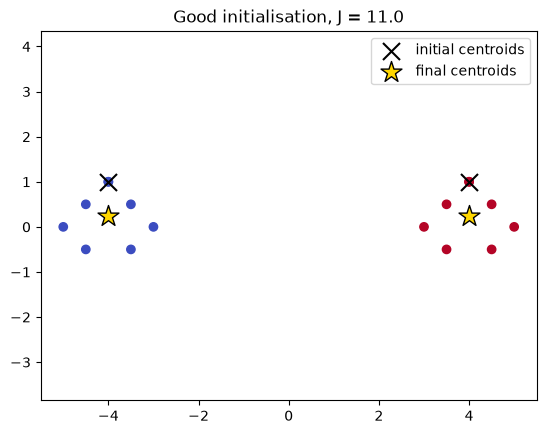

In [3]:
import numpy as np 
import matplotlib.pyplot as plt

# Draw the datset
A = np.array([[-4,1], [-5,0], [-3,0], [-4,1], [-4.5, 0.5], [-3.5, -0.5], [-4.5, -0.5], [-3.5, 0.5]])
# second clustet same array just shifted
B = A + np.array([8,0])
X = np.vstack([A,B])

def kmeans(X, mu, n_iter = 30):
    mu = mu.astype(float).copy()
    for _ in range(n_iter): 
        # how far is each centroid from each data
        distance = np.linalg.norm(X[:, None, :] - mu[None, :, :], axis = 2)
        cluster = distance.argmin(axis = 1)
        # now compute the new centroid 
        new_mu = np.array([X[cluster == k].mean(axis = 0) for k in range(len(mu))])

        # did we already reach an equilibrium? 
        if np.allclose(new_mu, mu):
            break
        
        mu = new_mu
    J = np.sum((X - mu[cluster]) ** 2)
    return cluster, mu, J

# a good case 
mu0 = np.array([[-4,1], [4,1]])
clusters, mu, loss = kmeans(X, mu0)


plt.scatter(X[:, 0], X[:, 1], c=clusters, cmap="coolwarm")
plt.scatter(mu0[:, 0], mu0[:, 1], marker="x", s=150, c="black", label="initial centroids")
plt.scatter(mu[:, 0], mu[:, 1], marker="*", s=250, c="gold", edgecolors="black", label="final centroids")
plt.title(f"Good initialisation, J = {loss:.1f}")
plt.axis("equal")
plt.legend()
plt.show()

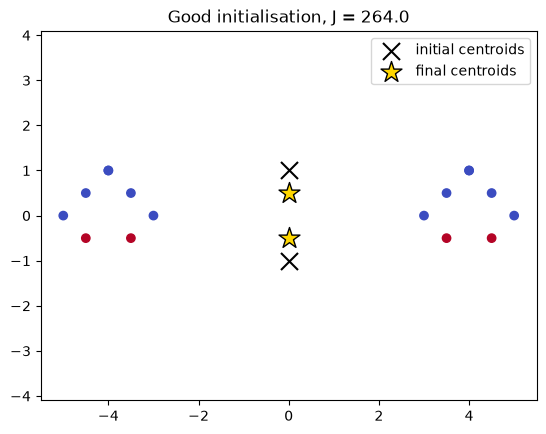

In [5]:
# a bad case 
# Explaination: If we take two points that sit on a line that is exactly in the middle of the two 
# data clusters the height distance will decide and the data gets splitted in the wrong way
mu0 = np.array([[0,1], [0,-1]])

clusters, mu, loss = kmeans(X, mu0)


plt.scatter(X[:, 0], X[:, 1], c=clusters, cmap="coolwarm")
plt.scatter(mu0[:, 0], mu0[:, 1], marker="x", s=150, c="black", label="initial centroids")
plt.scatter(mu[:, 0], mu[:, 1], marker="*", s=250, c="gold", edgecolors="black", label="final centroids")
plt.title(f"Good initialisation, J = {loss:.1f}")
plt.axis("equal")
plt.legend()
plt.show()

The initialisation matters since K-means only makes local improvements. With both centroids placed symmetrically between the clusters, every point is equally far from them horizontally, so the split is decided only by height. J is non-convex and can have several fixed points, where neither the assignment step nor the update step can improve the loss. K-means gives no guarantee of finding the best fixed point.

#### Question 10

What can you say about those configurations of centroids? What does it imply concerning the minima? Conclude your arguments by discussing the convexity of the problem.

I can say that the choice of the initialization matters a lot. The first initialization found the global minimum but the second stopped because it couldn't further improve the result. 
It implies that the bad configuartion was a local minimum that is not a gloabl. 
For a convex function, every local minimum is a global minimum. So this problem is not convex. 

#### Question 11

We can also quickly generalize our algorithm.

In some situations, you are aiming at favoring some directions in your data and penalizing the others, so that you can weigh the Euclidean distance according to:

$$d^{(w)}(x_{i}, \mu(i)) = \frac{\sum_{j=1}^d w_j(x_{ij} - \mu(i)_j)^2}{\sum_{j=1}^d w_j} $$

Assume $w_j > 0$ for every coordinate $j$.

Show that with a change of variables, the problem remains the same.

We can transform this weighted distance into plain Euclidian distance. 
W = $\sum_j w_j$, each coordinate: 

$$\tilde{x}_{ij} = \sqrt{(\frac{w_j}{W})}\, x_{ij} $$

$$\tilde{\mu}_j = \sqrt{(\frac{w_j}{W})}\, \mu_j  $$

Then $$d^{(w)}(x_i, \mu) = \sum_{j=1}^d \frac{w_j}{W}(x_{ij} - \mu(i)_j)^2 = \sum_{j=1}^d \left(\sqrt{\frac{w_j}{W}}x_{ij} - \sqrt{\frac{w_j}{W}}\mu(i)_j\right)^2 = || \tilde{x}_{ij} - \tilde{\mu}_j ||^2$$



This works since $w_j > 0$ for every j.

So the weighted loss is exactly the standard K-means loss in the new variables and each point gets assigned to the same cluster in both formulations. 
Since the change of variables is linear and invertible, it commutes with the mean. 
So the best centroid is still the empirical mean of the cluster jut rescaled. 
That means weighted distances is the same problem as the original one and J is still convex and non-increasing.  

### Part 2 — Restricted Boltzmann machines

#### Introduction

Boltzmann machines are inspired by models from thermodynamics and statistical physics. More precisely, they are energy-based models that use the well-known Boltzmann distribution, written in physics notation as:

$$ P\left( E \right)  = \frac{1}{Z} \exp \left( -\frac{E}{k_b T} \right)$$

In the statistical inference framework, this becomes:
$$
P(\mathbf{v} \mid J, \mathbf{b}) \propto e^{\mathbf{v}^\top J\mathbf{v} + \mathbf{b}^\top\mathbf{v}} = e^{-E(\mathbf{v})}
$$
where:

- $\mathbf{v}\in\mathbb{R}^n:$ The binary vector with components $v_i = 0 \; \text{or} \; 1$

- $J \in \mathbb{R}^{n \times n}:$ The coupling matrix

- $\mathbf{b} \in  \mathbb{R}^n$: Field

- $E(\mathbf{v}) \in  \mathbb{R}$: Energy

However, one problem arose with the original Boltzmann machine (BM) — as with its parent models in statistical physics (such as the SK model) — all the units interact through complicated dependencies. For example, if we consider 3 components of $\mathbf{v}$: $v_1$, $v_2$, and $v_3$, there are trivial interactions such as the one modeled by $P(v_1, v_2)$ corresponding to the correlation between the first two components of $\mathbf{v}$, but there are also nontrivial interactions. Indeed, a term such as $P(v_1, v_2 \mid v_3)$ suggests that the correlation between $x_1$ and $v_2$ depends on $v_3$ and this is clearly nonlinear.

A really ingenious way to overcome this situation is to replace all the tricky interactions between the units $\mathbf{v}\in\mathbb{R}^n$ by connections through hidden units $\mathbf{h}\in\mathbb{R}^m$, artificially created. Indeed, correlations between two units $v_1$ and $v_2$ (especially the dependence of their correlations on other units $v_3$, $v_4$,...) can be artificially replaced by introducing a third unit $h_1$ and considering only linear correlations between $v_1 \leftrightarrow h_1$, $h_1 \leftrightarrow v_2$ and $v_1 \leftrightarrow v_2$. The units $v_i$ are now called the visible units. This model is the best-known version of BMs.

<div style="text-align: center;">
    <img src="boltzmannmachine.png" alt="Diagram here" />
</div>

However, this model is still fully connected and makes the computation really costly. Then, one can even simplify the model by considering zero interactions within each layer. This simplified model is called a restricted Boltzmann machine (RBM) (Nobel Prize in Physics 2024 🥳).

Thus, the RBM architecture consists of two layers of binary stochastic units: a **visible layer** $\mathbf{v}$ and a **hidden layer** $\mathbf{h}$. The layers are fully connected, but there are no connections within a layer, making the model a **bipartite graph**.

<div style="text-align: center;">
    <img src="rbm.png" alt="Diagram here" />
</div>

Restricted Boltzmann Machines (RBMs) are a class of energy-based probabilistic graphical models that are commonly used in machine learning for tasks such as dimensionality reduction, feature learning, and generative modeling.

#### Energy function and probabilities

The joint configuration of the visible units $\mathbf{v} \in \{0, 1\}^d$ and the hidden units $\mathbf{h} \in \{0, 1\}^m$ is associated with an **energy function**, defined as:

$$ E(\mathbf{v}, \mathbf{h}) = -\mathbf{v}^\top \mathbf{W} \mathbf{h} - \mathbf{b}^\top \mathbf{v} - \mathbf{c}^\top \mathbf{h}$$
where:

- $\mathbf{W} \in \mathbb{R}^{d \times m}$ is the weight matrix connecting the visible and hidden units,
- $\mathbf{b} \in \mathbb{R}^d$ is the field of the visible units, also called their biases,
- $\mathbf{c} \in \mathbb{R}^m$ is the field of the hidden units, also called their biases.

The energy function determines the joint probability distribution over $\mathbf{v}$ and $\mathbf{h}$:
$$ P(\mathbf{v}, \mathbf{h}) = \frac{1}{Z} \exp(-E(\mathbf{v}, \mathbf{h})) $$
where $Z$ is the **partition function**, ensuring normalization:

$$ Z = \sum_{\mathbf{v}, \mathbf{h}} \exp(-E(\mathbf{v}, \mathbf{h})) $$

The marginal probability of the visible units $\mathbf{v}$ is obtained by summing over all possible configurations of the hidden units:

$$ P(\mathbf{v}) = \frac{1}{Z} \sum_{\mathbf{h}} \exp(-E(\mathbf{v}, \mathbf{h})). $$

#### Question 12

Write a valid expression of the energy $E(\mathbf{v}, \mathbf{h})$ in the case of a BM (non-restricted) with a hidden layer.

$$ E(\mathbf{v}, \mathbf{h}) = -\mathbf{v}^\top \mathbf{W} \mathbf{h} - \frac{1}{2} \mathbf{v}^\top \mathbf{L} \mathbf{v}   -\frac{1}{2} \mathbf{h}^\top \mathbf{J} \mathbf{h} - \mathbf{b}^\top \mathbf{v} - \mathbf{c}^\top \mathbf{h}$$
where:

- $\mathbf{W} \in \mathbb{R}^{d \times m}$ is the weight matrix connecting the visible and hidden units,
- $\mathbf{L} \in \mathbb{R}^{d \times d}$ is the weight matrix connecting the visible and visible units,
- $\mathbf{J} \in \mathbb{R}^{m \times m}$ is the weight matrix connecting the hidden and hidden units,
- $\mathbf{b} \in \mathbb{R}^d$ is the field of the visible units, also called their biases,
- $\mathbf{c} \in \mathbb{R}^m$ is the field of the hidden units, also called their biases.

#### Conditional independence

#### Question 13

One of the key properties of RBMs is the **conditional independence** between units within a layer:

Compute the conditional probability and show that:

$$ P(h_j = 1 \mid \mathbf{v}) = \sigma\left(c_j + \sum_{i} v_i W_{ij}\right) $$
and
$$ P(v_i = 1 \mid \mathbf{h}) = \sigma\left(b_i + \sum_{j} h_j W_{ij}\right) $$

where $\sigma(x) = \frac{1}{1 + e^{-x}}$ is the sigmoid activation function.

This bipartite structure enables efficient Gibbs sampling for approximating the intractable joint distribution $P(\mathbf{v}, \mathbf{h})$.

$$-E(\mathbf{v}, \mathbf{h}) = \mathbf{b}^\top \mathbf{v} + \sum_{k} h_k \left(c_k + \sum_{i} v_i W_{ik}\right) \;\Rightarrow\; \exp(-E(\mathbf{v}, \mathbf{h})) = e^{\mathbf{b}^\top \mathbf{v}} \prod_{k} e^{h_k \left(c_k + \sum_{i} v_i W_{ik}\right)}$$

$$ P(h_j = 1 | v) = \frac{P(h_j = 1 , v)}{P(v)} = \frac{\frac{1}{Z} \sum_{\mathbf{h}_{-j}} \exp(-E(\mathbf{v}, \mathbf{h}_{-j}, \mathbf{h_j = 1}))}{ \frac{1}{Z} \sum_{\mathbf{h}} \exp(-E(\mathbf{v}, \mathbf{h}))}$$

$$ = \frac{e^{\mathbf{b}^\top \mathbf{v}} \, e^{c_j + \sum_{i} v_i W_{ij}} \prod_{k \neq j} \sum_{h_k \in \{0,1\}} e^{h_k \left(c_k + \sum_{i} v_i W_{ik}\right)}}{e^{\mathbf{b}^\top \mathbf{v}} \sum_{h_j \in \{0,1\}} e^{h_j \left(c_j + \sum_{i} v_i W_{ij}\right)} \prod_{k \neq j} \sum_{h_k \in \{0,1\}} e^{h_k \left(c_k + \sum_{i} v_i W_{ik}\right)}}$$

$$ = \frac{\exp(-E(\mathbf{v}, \mathbf{h_j = 1}))}{ \sum_{h_j \in \{0,1\}} \exp(-E(\mathbf{v}, \mathbf{h_j}))}$$

$$ = \frac{\exp(-E(\mathbf{v}, \mathbf{h_j = 1}))}{\exp(-E(\mathbf{v}, \mathbf{h_j = 0})) + \exp(-E(\mathbf{v}, \mathbf{h_j = 1})) }$$

$$ = \frac{1}{1 + e^{E(\mathbf{v}, \mathbf{h_j = 1})-E(\mathbf{v}, \mathbf{h_j = 0})}}$$

Now I put $h_j = 0$ and $h_j = 1$ in the formula for E(v, h). 

$$E(v, h_j=0) = -\mathbf{b}^\top \mathbf{v}$$
$$ E(v, h_j = 1) = \sum_{i} -v_i W_{ij} - \mathbf{b}^\top \mathbf{v} - c_j$$

$$ E(\mathbf{v}, \mathbf{h_j = 1})-E(\mathbf{v}, \mathbf{h_j = 0}) = \sum_{i} -v_i W_{ij} - c_j$$

So we indeed have: 

$$P(h_j = 1 | v) = \frac{1}{1 + e^{\sum_{i} -v_i W_{ij} - c_j}} =\sigma\left(c_j + \sum_{i} v_i W_{ij}\right) $$

$$P(\mathbf{h} | \mathbf{v}) = \prod_j P(h_j | \mathbf{v})$$

$$-E(\mathbf{v}, \mathbf{h}) = \mathbf{c}^\top \mathbf{h} + \sum_{l} v_l \left(b_l + \sum_{j} h_j W_{lj}\right) \;\Rightarrow\; \exp(-E(\mathbf{v}, \mathbf{h})) = e^{\mathbf{c}^\top \mathbf{h}} \prod_{l} e^{v_l \left(b_l + \sum_{j} h_j W_{lj}\right)}$$

$$ P(v_i = 1 | h) = \frac{P(v_i = 1 , h)}{P(h)} = \frac{\frac{1}{Z} \sum_{\mathbf{v}_{-i}} \exp(-E(\mathbf{v}_{-i}, \mathbf{v_i = 1}, \mathbf{h}))}{ \frac{1}{Z} \sum_{\mathbf{v}} \exp(-E(\mathbf{v}, \mathbf{h}))}$$

$$ = \frac{e^{\mathbf{c}^\top \mathbf{h}} \, e^{b_i + \sum_{j} h_j W_{ij}} \prod_{l \neq i} \sum_{v_l \in \{0,1\}} e^{v_l \left(b_l + \sum_{j} h_j W_{lj}\right)}}{e^{\mathbf{c}^\top \mathbf{h}} \sum_{v_i \in \{0,1\}} e^{v_i \left(b_i + \sum_{j} h_j W_{ij}\right)} \prod_{l \neq i} \sum_{v_l \in \{0,1\}} e^{v_l \left(b_l + \sum_{j} h_j W_{lj}\right)}}$$

$$ = \frac{\exp(-E(\mathbf{v_i = 1}, \mathbf{h}))}{ \sum_{v_i \in \{0,1\}} \exp(-E(\mathbf{v_i}, \mathbf{h}))}$$

$$ = \frac{\exp(-E(\mathbf{v_i = 1}, \mathbf{h}))}{\exp(-E(\mathbf{v_i = 0}, \mathbf{h})) + \exp(-E(\mathbf{v_i = 1}, \mathbf{h})) }$$

$$ = \frac{1}{1 + e^{E(\mathbf{v_i = 1}, \mathbf{h})-E(\mathbf{v_i = 0}, \mathbf{h})}}$$

Now I put $v_i = 0$ and $v_i = 1$ in the formula for E(v, h). 

$$E(v_i=0, h) = -\mathbf{c}^\top \mathbf{h}$$
$$ E(v_i = 1, h) = \sum_{j} -h_j W_{ij} - b_i - \mathbf{c}^\top \mathbf{h}$$

$$ E(\mathbf{v_i = 1}, \mathbf{h})-E(\mathbf{v_i = 0}, \mathbf{h}) = \sum_{j} -h_j W_{ij} - b_i$$

So we indeed have: 

$$P(v_i = 1 | h) = \frac{1}{1 + e^{\sum_{j} -h_j W_{ij} - b_i}} =\sigma\left(b_i + \sum_{j} h_j W_{ij}\right) $$

$$P(\mathbf{v} | \mathbf{h}) = \prod_i P(v_i | \mathbf{h})$$

#### Learning in RBMs

#### Question 14

Training an RBM involves maximizing the likelihood of the data distribution. To do so, we aim to use gradient descent/ascent on the weights (and biases).

Compute the log-likelihood $\mathcal{L}(\mathbf{v})$. Recall that this is an unsupervised learning model.

#### Question 15

Compute the gradient of the log-likelihood with respect to the weights $\mathbf{W}$ and the biases $\mathbf{b}$, $\mathbf{c}$:

Now, it should be possible to implement the RBM!

#### Question 16 (open question)

While it seems possible to run the RBM algorithm, note that the second term in the gradient with respect to $\mathbf{W}$ is computationally expensive due to the intractability of $Z$. The contrastive divergence approximation (CD-$k$) is often used. Research this approximation. Is it sufficient, and why? Explain in your own words and cite the papers you consulted.

#### Applications of RBMs

RBMs are widely used in tasks such as:

- **Dimensionality reduction**: Similar to PCA but capable of capturing non-linear structures,
- **Feature learning**: For pre-training deep neural networks,
- **Collaborative filtering**: Used in recommendation systems.

Transparency: 

Since I have seen and done the proof for Q5 many times before and couldn't earn a positive reward for my learning through it, I let Opus 5.5 write it. That was my prompt: 
"for 5 write the algebraic proof. with adding it in and subtracting showing c must be equal to empricial mean"

Same applies to P(v_j = 1 | h). That was my prompt: "write the proof P(v_j = 1 |h) exactly in my style in the second markdown, use the same structure.". I have done both on paper but writing everything down with LaTex took me a long time for the first one, so I didn't want to repeat the writing again. 